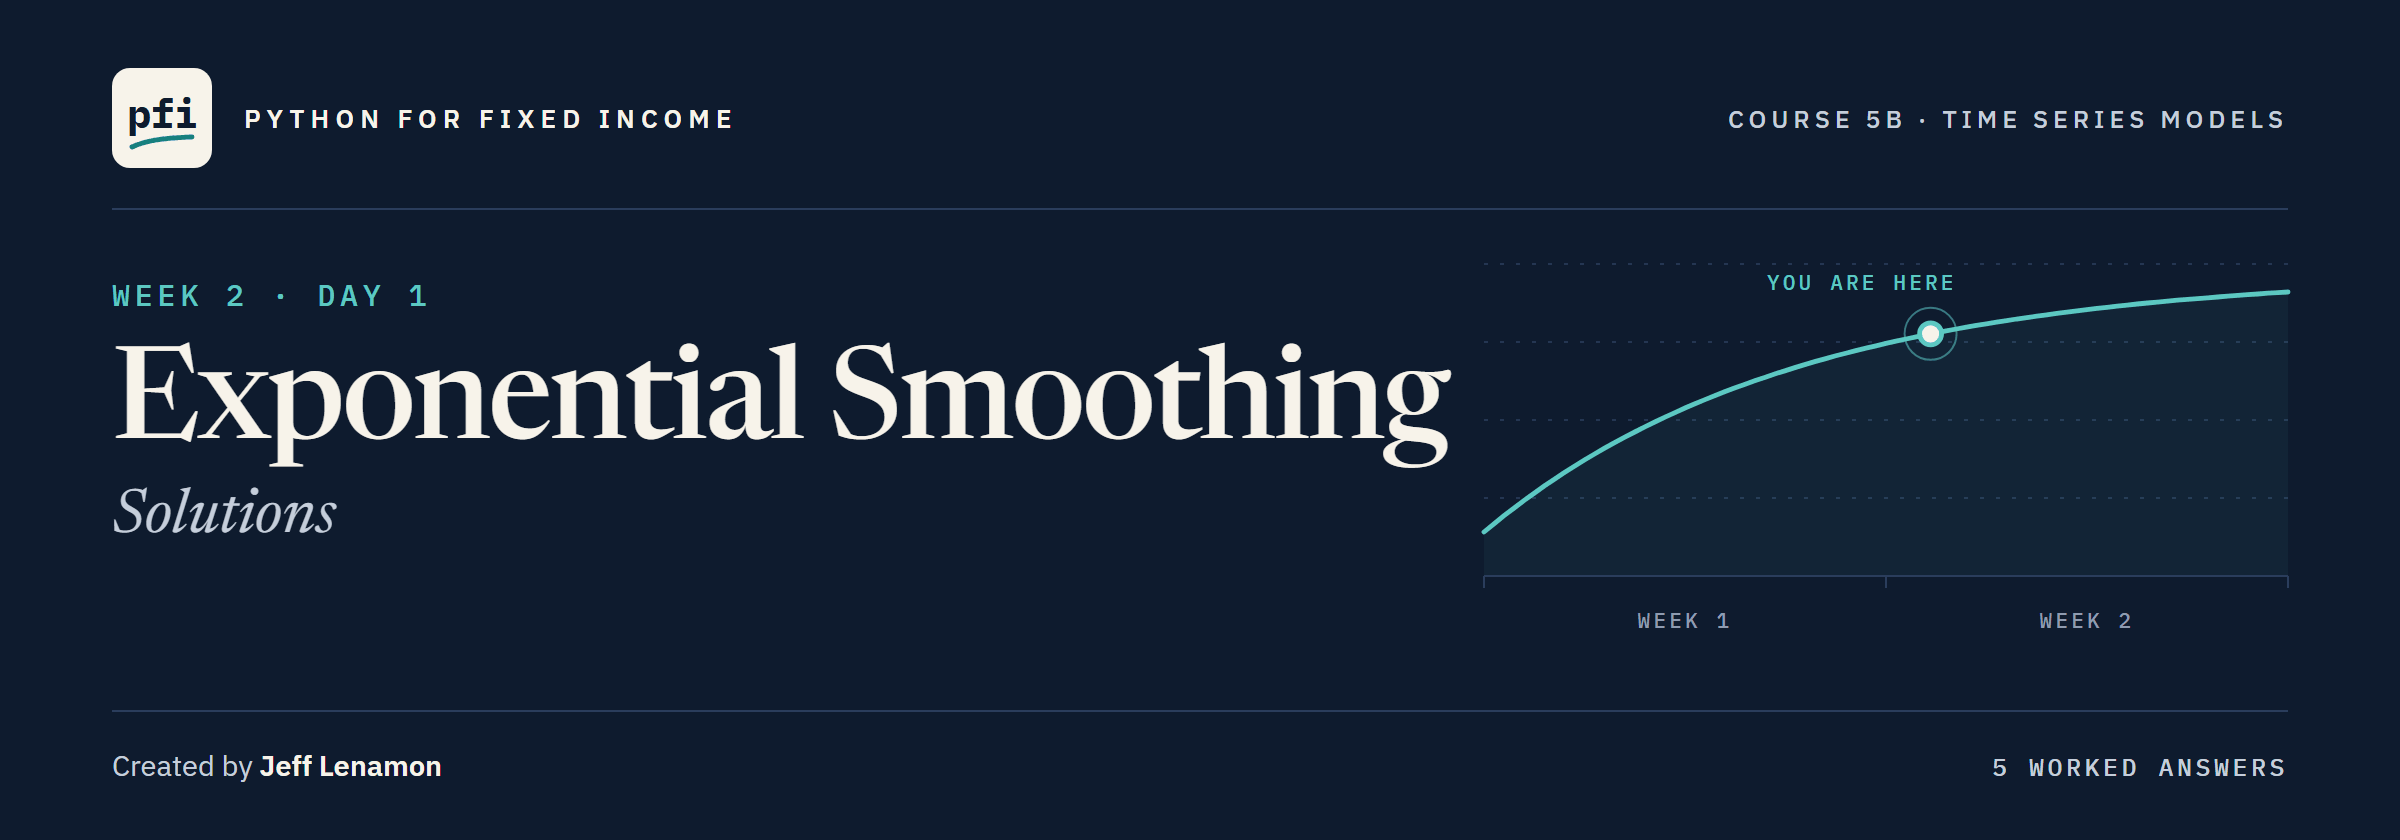

# Exponential Smoothing: Solutions

Week 2, Day 1. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day1/06_exponential_smoothing_solutions.ipynb)

# Problem Statement

## Business Context

Week 1 ended with no model of a series' own past closer to each date's change than the last value carried forward, neither Day 2's drift nor Day 5's ARIMA.
Week 2 opens with the oldest family of all, exponential smoothing: an average that weights the newest row most and lets older rows fade.
RiskMetrics, a risk method published in 1996, runs the same one-line recursion to describe volatility.
Today we fit it to the level of five series, score it walk-forward against Day 2's bar, then point it at the size of a change.
As on every day of this course, each output is a value for a date inside the file from the rows before it, never a forecast of rates or spreads.

## Objectives

Write the exponentially weighted moving average as a loop, match pandas, and read its alpha as weights and a half-life.
Fit simple smoothing, Holt's trend and the damped trend with `ExponentialSmoothing`, and read alpha, beta and phi.
Turn a fitted smoother into one-step values that use only earlier rows, and score smoothers walk-forward with MASE beside Day 2's bar and Day 5's AR(1).
Build an EWMA volatility of the daily changes, draw its band, and score the smoothed size of a change.

## Data Dictionary

`treasury_par_yields.csv`, one row per trading day:

1. `date`: the trading day, the index
2. `2 Yr`, `10 Yr`: par yields, in percent

`course3_synthetic_spreads.csv`, the same dates:

3. `ig_spread_bp`, `hy_spread_bp`: synthetic IG and HY spreads, in bp

Made here as on Day 2, all in bp: `levels` (the `2 Yr`, `10 Yr`, `2s10s`, `IG` and `HY`), `changes`, and the five `folds`.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# Day 2's folds and score, the smoothers, and Day 5's ARIMA
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Loading the Data

## Reading the Two Files and Cutting the Years

In [3]:
# the Treasury par yields in percent and the synthetic spreads in bp, one row per trading day
yields = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# Day 2's cut: the development years only, so the held-out years stay closed
CUT = "2022-12-30"
development = yields.loc[:CUT]

In [4]:
# Day 2's five series, all in bp: a yield in percent times 100, the slope as 10 Yr less 2 Yr
levels = pd.DataFrame({"2 Yr": (development["2 Yr"] * 100).round(2),
                       "10 Yr": (development["10 Yr"] * 100).round(2),
                       "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
                       "IG": spreads.loc[:CUT, "ig_spread_bp"],
                       "HY": spreads.loc[:CUT, "hy_spread_bp"]})

# each day's change in bp: the level less the level one row before
changes = levels.diff().dropna()

## The Five Folds and the Bar

Day 2's five walk-forward folds test 252 dates each.
The last value carried forward has a fitted change of 0, so its MAE on a fold is the average size of that fold's changes.

In [5]:
# Day 2's five folds, and the last value's MAE on each fold's test dates, in bp: the bar
folds = list(TimeSeriesSplit(n_splits=5, test_size=252).split(changes))
bar = pd.DataFrame({f"fold {k}": changes.iloc[test].abs().mean() for k, (train, test) in enumerate(folds, start=1)})
bar["average"] = bar.mean(axis=1)
bar

,fold 1,fold 2,fold 3,fold 4,fold 5,average
2 Yr,2.0675,3.4881,1.9008,1.4881,6.0675,3.0024
10 Yr,2.6905,3.4444,3.6627,3.3056,6.2579,3.8722
2s10s,1.8214,1.6468,2.7222,2.8016,3.8413,2.5667
IG,0.7349,0.8448,0.7603,1.0115,1.2087,0.9121
HY,3.3321,3.0635,3.2437,5.0127,5.0329,3.9370


Day 2's numbers, recomputed: the 10 Yr's folds run from 2.69 to 6.26 bp, an average of 3.87.

The folds disagree by 0.47 bp on IG and by 4.58 bp on the 2 Yr.

**Every rule today sits beside this table.**

# Data Overview

## Checking the Shape

In [6]:
# levels, changes, blank cells, and the dates the five folds score
print("Levels:", levels.shape, "| changes:", changes.shape, "| blank cells:", changes.isna().sum().sum())
print("Scored dates:", changes.index[folds[0][1][0]].date(), "to", changes.index[-1].date())

Levels: (2001, 5) | changes: (2000, 5) | blank cells: 0
Scored dates: 2017-12-15 to 2022-12-30


**Five complete series: the smoothers read the levels, and every score reads the changes.**

# The EWMA by Hand

![Three rows of the exponentially weighted moving average side by side, rows t - 1, t and t + 1. Each row's level feeds down into that row's average times alpha, and each row's average feeds right into the next row's average times 1 - alpha. Under them the one line: new average = alpha x today's level + (1 - alpha) x old average](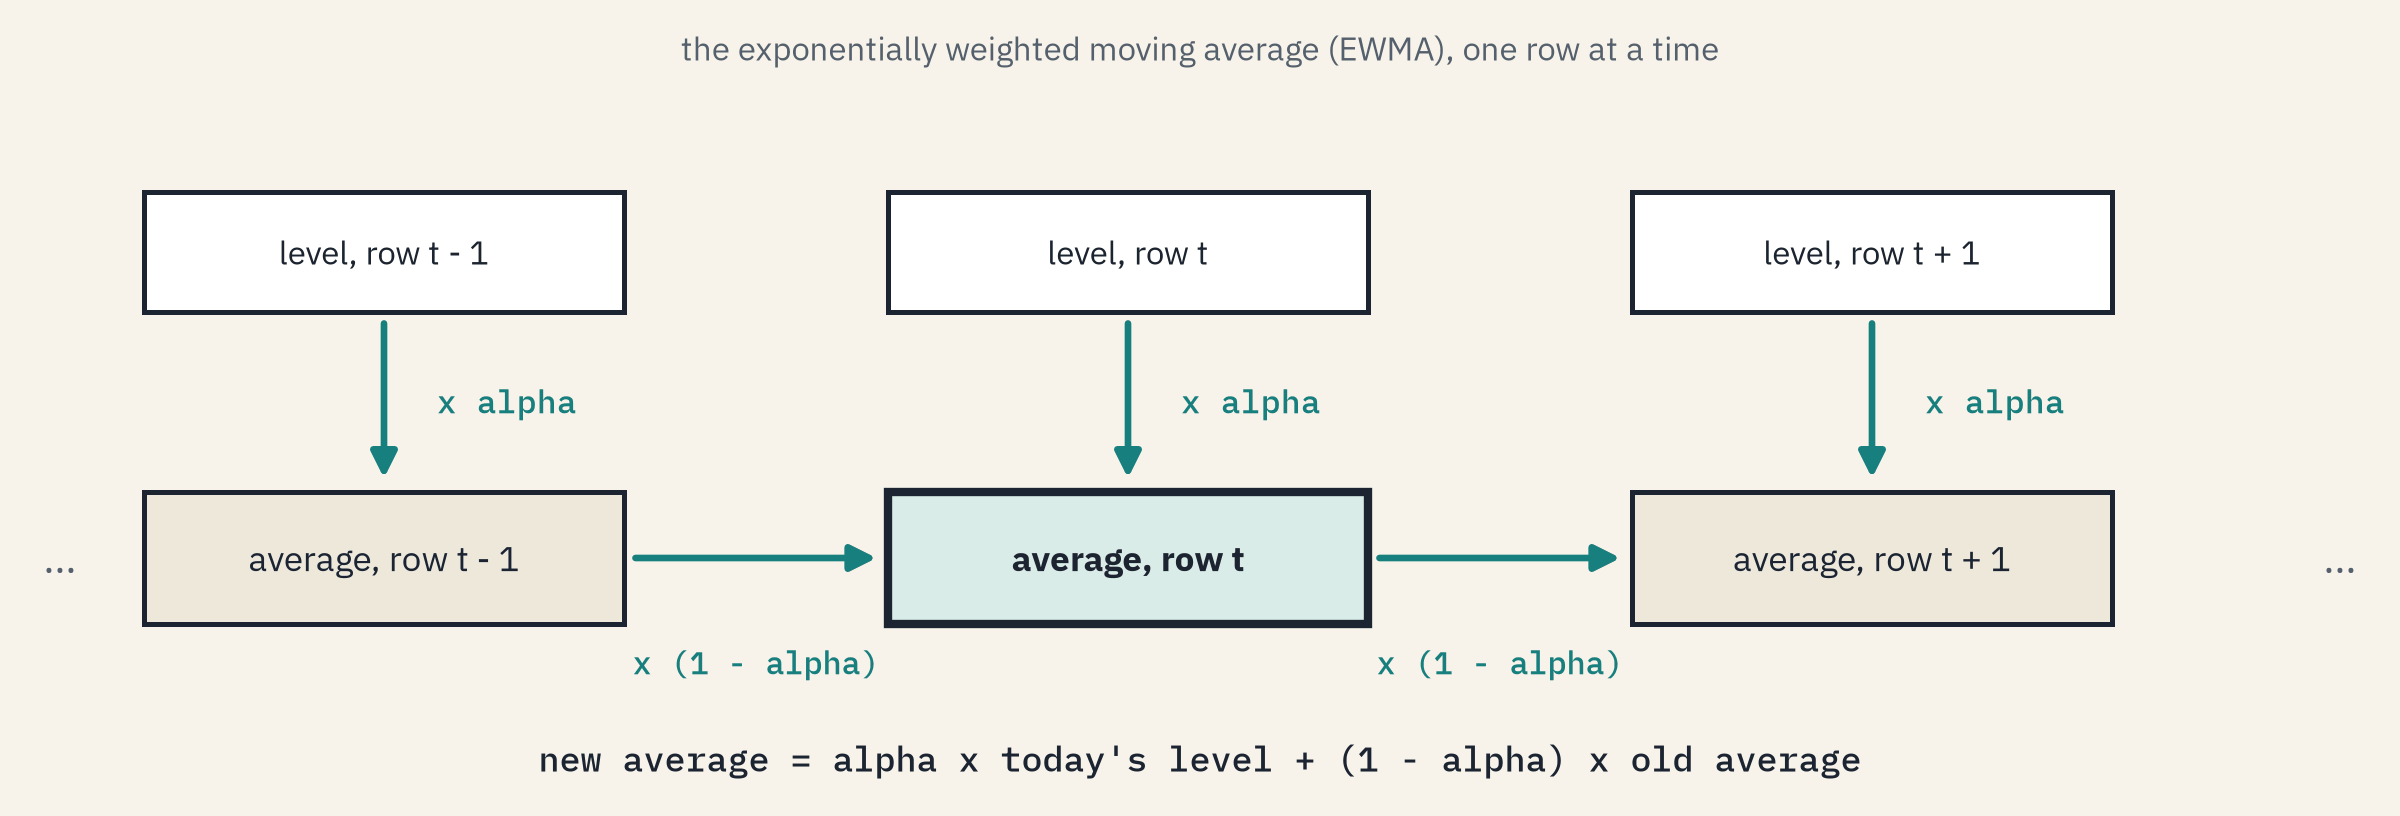)

An **exponentially weighted moving average** (EWMA) keeps one number, the average, and updates it row by row.
The new average is alpha times today's level plus (1 - alpha) times the old average.
**alpha**, between 0 and 1, is the weight on the newest row.

## A Loop of Three Lines

In [7]:
# the 10 Yr's levels as a plain array, and an alpha of 0.2
ten = levels["10 Yr"].to_numpy()
alpha = 0.2

# start at the first level, then each row: alpha times today plus (1 - alpha) times the old average
average = [ten[0]]
for level in ten[1:]:
    average.append(alpha * level + (1 - alpha) * average[-1])

pandas has the same average built in: `.ewm(alpha=...)` sets the weights and `.mean()` takes the average.

In [8]:
# pandas' EWMA: adjust=False runs the recursion exactly as the loop does
by_pandas = levels["10 Yr"].ewm(alpha=0.2, adjust=False).mean()
print("Largest gap between the loop and pandas:", np.abs(np.array(average) - by_pandas.to_numpy()).max(), "bp")

Largest gap between the loop and pandas: 0.0 bp


The loop and pandas agree on all 2,001 dates.

`adjust=False` is the recursion as written; the default, `adjust=True`, rescales the weights of the first rows.

## Where the Average Looks

Each row multiplies every older weight by (1 - alpha), so the row k back carries alpha (1 - alpha)^k of the average.
A weight's **half-life** is the number of rows after which it has fallen to half the newest row's: ln 0.5 / ln(1 - alpha).

In [9]:
# for four alphas: the half-life of a weight in rows, and the share of the weight on the newest 20 rows
for a in [0.05, 0.2, 0.5, 0.9]:
    half_life = np.log(0.5) / np.log(1 - a)
    newest_20 = 1 - (1 - a) ** 20
    print(f"alpha {a}: half-life {half_life:.2f} rows | newest 20 rows: {newest_20 * 100:.1f} percent of the weight")

alpha 0.05: half-life 13.51 rows | newest 20 rows: 64.2 percent of the weight
alpha 0.2: half-life 3.11 rows | newest 20 rows: 98.8 percent of the weight
alpha 0.5: half-life 1.00 rows | newest 20 rows: 100.0 percent of the weight
alpha 0.9: half-life 0.30 rows | newest 20 rows: 100.0 percent of the weight


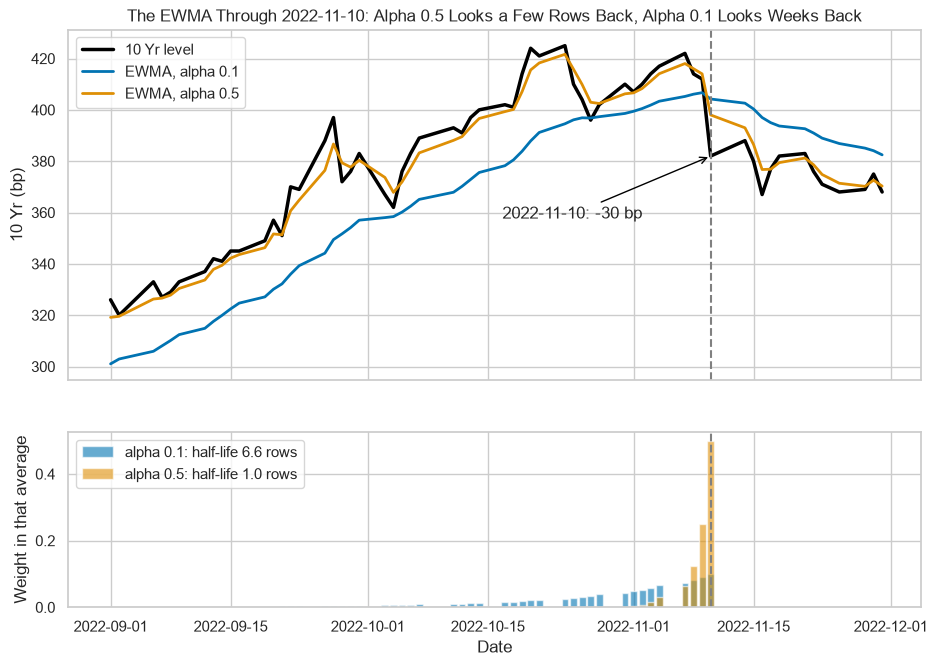

In [10]:
# top: the 10 Yr and two EWMAs, Sept to Nov 2022; bottom: the weight each earlier date gets in 2022-11-10's average
window = levels.loc["2022-09-01":"2022-11-30", "10 Yr"]
day = pd.Timestamp("2022-11-10")
back = np.arange(len(window.loc[:day]))[::-1]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, height_ratios=[2, 1])
top.plot(window, color="black", linewidth=2.5, label="10 Yr level")
for a, colour in [(0.1, "C0"), (0.5, "C1")]:
    top.plot(levels["10 Yr"].ewm(alpha=a, adjust=False).mean()[window.index], color=colour, linewidth=2, label=f"EWMA, alpha {a}")
    bottom.bar(window.loc[:day].index, a * (1 - a) ** back, color=colour, alpha=0.6,
               label=f"alpha {a}: half-life {np.log(0.5) / np.log(1 - a):.1f} rows")
top.annotate(f"2022-11-10: {changes.loc[day, '10 Yr']:.0f} bp", (day, window[day]), xytext=(-150, -45), textcoords="offset points",
             arrowprops={"arrowstyle": "->", "color": "black"})
top.axvline(day, color="gray", linestyle="--")
bottom.axvline(day, color="gray", linestyle="--")
top.set(ylabel="10 Yr (bp)", title="The EWMA Through 2022-11-10: Alpha 0.5 Looks a Few Rows Back, Alpha 0.1 Looks Weeks Back")
bottom.set(ylabel="Weight in that average", xlabel="Date")
top.legend(loc="upper left")
bottom.legend(loc="upper left")
plt.show()

On 2022-11-10 the 10 Yr fell 30 bp, Day 2's largest daily move of the development years.

At alpha 0.5 the average drops half way that day: its weight sits on the last few rows, with a half-life of one row.

At alpha 0.1 the weight spreads back into October, with a half-life of 6.6 rows, so the average barely moves and stays above the level for weeks.

## Your Turn: Slide Alpha

In [11]:
# your turn: move alpha and watch the average follow the 10 Yr through 2022
def draw_alpha(alpha=0.1):
    year = levels.loc["2022", "10 Yr"]
    average = levels["10 Yr"].ewm(alpha=alpha, adjust=False).mean().loc["2022"]
    plt.plot(year, color="black", label="10 Yr level")
    plt.plot(average, color="C0", linewidth=2, label=f"EWMA, alpha {alpha:.2f}")
    plt.xlabel("Date")
    plt.ylabel("10 Yr (bp)")
    plt.title(f"Alpha {alpha:.2f}: the Average Sits {(year - average).abs().mean():.2f} bp From the Level, on Average Over 2022")
    plt.legend(loc="upper left")
    plt.show()

interact(draw_alpha, alpha=(0.02, 1.0, 0.02));

interactive(children=(FloatSlider(value=0.1, description='alpha', max=1.0, min=0.02, step=0.02), Output()), _d…

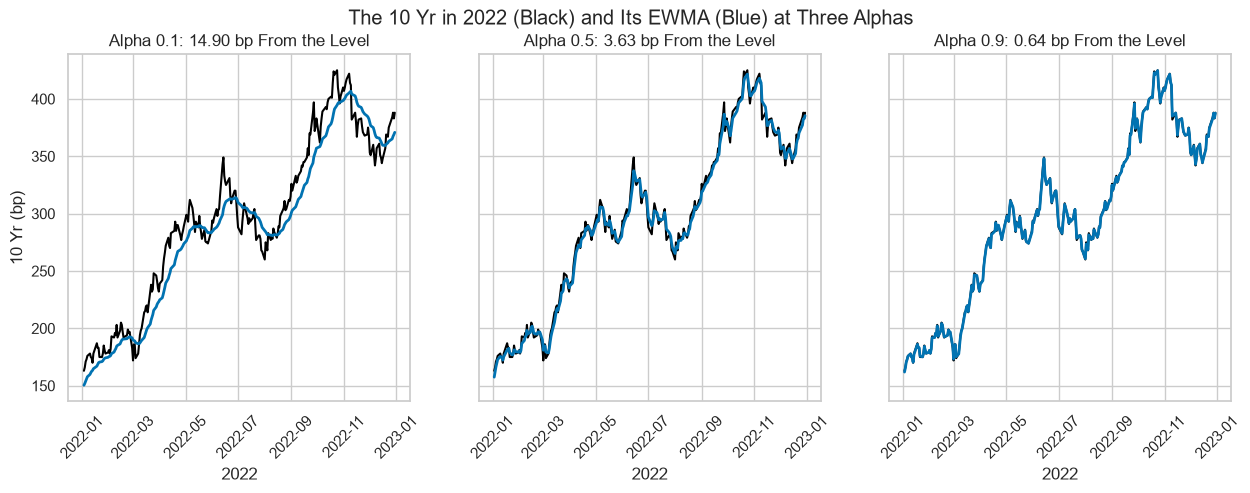

In [12]:
# the slider's starting position, alpha 0.1, beside 0.5 and 0.9, drawn as a still picture (sliders do not run on GitHub)
year = levels.loc["2022", "10 Yr"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, a in zip(axes, [0.1, 0.5, 0.9]):
    average = levels["10 Yr"].ewm(alpha=a, adjust=False).mean().loc["2022"]
    ax.plot(year, color="black")
    ax.plot(average, color="C0", linewidth=2)
    ax.set(title=f"Alpha {a}: {(year - average).abs().mean():.2f} bp From the Level", xlabel="2022")
    ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("10 Yr (bp)")
fig.suptitle("The 10 Yr in 2022 (Black) and Its EWMA (Blue) at Three Alphas")
plt.show()

### Interpretation of Alpha

A small alpha is smooth and late: at 0.1 the average sits 14.90 bp from the level, on average over 2022.

A large alpha follows closely: 0.64 bp at 0.9, and at 1 the average is the level itself.

**The average through a date includes that date; to use it as a value for a date, shift it one row. Which alpha suits a value for a date is for the data to say.**

# Simple Exponential Smoothing

**Simple exponential smoothing** is the EWMA used as the value for the next row.
It fits two numbers by least squares on the training rows: alpha, and the **starting level** the average begins from.
Least squares picks the pair with the smallest **sum of squared one-step misses**, each miss a level less the average through the row before.
statsmodels' `ExponentialSmoothing` fits it on the plain values, `.to_numpy()`, as every statsmodels model in this course is.

**Predict 1**

Fold 1's training dates end on 2017-12-14, which leaves 741 levels of the 10 Yr.

Q. What alpha does least squares give the 10 Yr on those 741 levels? Write down a number between 0 and 1.

## Fitting Alpha on Fold 1's Training Years

In [13]:
# fold 1's dates, and the 10 Yr's levels up to its last training date
train, test = changes.index[folds[0][0]], changes.index[folds[0][1]]
fold1_levels = levels.loc[:train[-1], "10 Yr"]

# simple smoothing: no trend; alpha and the starting level fitted by least squares
simple = ExponentialSmoothing(fold1_levels.to_numpy(), initialization_method="estimated").fit()
print(len(fold1_levels), "levels | alpha:", round(simple.params["smoothing_level"], 4))
print("Starting level:", round(simple.params["initial_level"], 2), "bp | the first level:", fold1_levels.iloc[0], "bp")

741 levels | alpha: 0.9364
Starting level: 211.46 bp | the first level: 212.0 bp


Alpha is 0.9364: each average keeps only about 6 percent of the old one.

The starting level, 211.46 bp, sits half a bp from the first level.

## The Bowl

In [14]:
# the sum of squared one-step misses on fold 1's training levels, for each alpha and each series
alphas = np.round(np.arange(0.02, 1.001, 0.02), 2)
bowl = pd.DataFrame(index=alphas, columns=levels.columns, dtype=float)
for name in levels.columns:
    fold1 = levels.loc[:train[-1], name]
    for a in alphas:
        bowl.loc[a, name] = ((fold1 - fold1.ewm(alpha=a, adjust=False).mean().shift(1)) ** 2).sum()
print("Lowest at alpha:", bowl.idxmin().to_dict())

Lowest at alpha: {'2 Yr': 0.86, '10 Yr': 0.94, '2s10s': 0.94, 'IG': 0.88, 'HY': 0.94}


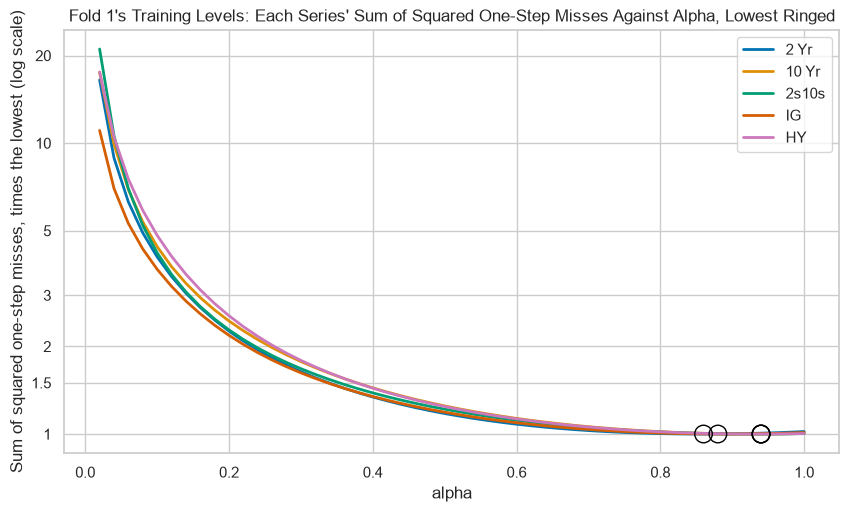

In [15]:
# each series' bowl as a multiple of its own lowest sum, on a log axis, the lowest ringed
cost = bowl / bowl.min()
fig, ax = plt.subplots(figsize=(10, 5.5))
for name in cost.columns:
    ax.plot(cost.index, cost[name], linewidth=2, label=name)
    ax.scatter(cost[name].idxmin(), 1, s=160, facecolor="none", edgecolor="black", zorder=3)
ax.set_yscale("log")
ax.set(yticks=[1, 1.5, 2, 3, 5, 10, 20], yticklabels=["1", "1.5", "2", "3", "5", "10", "20"], xlabel="alpha",
       ylabel="Sum of squared one-step misses, times the lowest (log scale)")
ax.minorticks_off()
ax.set_title("Fold 1's Training Levels: Each Series' Sum of Squared One-Step Misses Against Alpha, Lowest Ringed")
ax.legend()
plt.show()

In [16]:
# how much more a sum costs at alpha 0.1 and at alpha 1 than at its lowest
cost.loc[[0.1, 1.0]]

,2 Yr,10 Yr,2s10s,IG,HY
0.1000,4.0660,4.4095,4.1991,3.6848,4.8191
1.0000,1.0197,1.0038,1.0038,1.0119,1.0043


Every bowl bottoms out between 0.86 and 0.94.

Alpha 0.1 costs 3.7 to 4.8 times the lowest sum, while alpha 1 costs only 0.4 to 2.0 percent more.

### Interpretation of Alpha Near 1

An average that keeps a few percent of its past is close to the last level: a level near a random walk (Day 3) has little to smooth.

Simple smoothing is an ARIMA(0, 1, 1) in Day 5's terms, one difference and one MA term, with theta = alpha - 1.

In [17]:
# an ARIMA(0, 1, 1) on the same levels: one difference and one MA term, its theta beside alpha - 1
arima_011 = ARIMA(fold1_levels.to_numpy(), order=(0, 1, 1)).fit(method_kwargs={"warn_convergence": False})
print("converged", arima_011.mle_retvals["converged"], "| theta:", round(arima_011.params[0], 4),
      "| alpha - 1:", round(simple.params["smoothing_level"] - 1, 4))

converged True | theta: -0.0635 | alpha - 1: -0.0636


Two fitting routes, one model: theta -0.0635 against alpha - 1 of -0.0636.

## One-Step Values That Use Only Earlier Rows

The one-step value for a date is the average through the row before, `.shift(1)`, and its fitted change is that value less the level on the row before.

In [18]:
# fold 1's alpha, and Day 2's cut test on the EWMA with and without the shift
alpha_hat = simple.params["smoothing_level"]
blanked = levels["10 Yr"].copy()
blanked.loc["2019-12-31":] = np.nan
for shift in [1, 0]:
    whole = levels["10 Yr"].ewm(alpha=alpha_hat, adjust=False).mean().shift(shift).loc[:"2019-12-31"]
    stopped = blanked.ewm(alpha=alpha_hat, adjust=False).mean().shift(shift).loc[:"2019-12-31"]
    print("shift", shift, "| equal:", whole.equals(stopped), "|", len(whole.compare(stopped)), "of", len(whole), "values moved")

shift 1 | equal: True | 0 of 1250 values moved
shift 0 | equal: False | 1 of 1250 values moved


Shifted, none of the 1,250 values up to the cut moves.

Unshifted, the cut date's own value moves: the average through a date reads that date.

## The First Score

In [19]:
# fold 1's test dates: the one-step value less the level on the row before is the fitted change
one_step = levels["10 Yr"].ewm(alpha=alpha_hat, adjust=False).mean().shift(1)
fitted_change = (one_step - levels["10 Yr"].shift(1))[test]
actual = changes["10 Yr"][test]
print("Simple smoothing MAE:", round(mean_absolute_error(actual, fitted_change), 3), "bp | last value:", round(bar.loc["10 Yr", "fold 1"], 3), "bp")
print("Average size of a fitted change:", round(fitted_change.abs().mean(), 2), "bp | of an actual change:", round(actual.abs().mean(), 2), "bp")

Simple smoothing MAE: 2.698 bp | last value: 2.69 bp
Average size of a fitted change: 0.17 bp | of an actual change: 2.69 bp


On 252 dates it never read, simple smoothing misses by 2.698 bp a date, the last value by 2.690.

Its fitted change averages 0.17 bp against changes of 2.69: the value sits a hair off the last level.

**Least squares keeps a little averaging; whether that helps on later dates needs all five folds.**

# Holt's Trend and the Damped Trend

![Holt's linear trend keeps two numbers each row. The level is alpha x today's level + (1 - alpha) x (old level + phi x old trend). The trend is beta x (new level - old level) + (1 - beta) x phi x old trend. The value for the next row is level + phi x trend. Holt has phi = 1, so the trend carries on unchanged; the damped trend has phi below 1, so the trend fades row by row](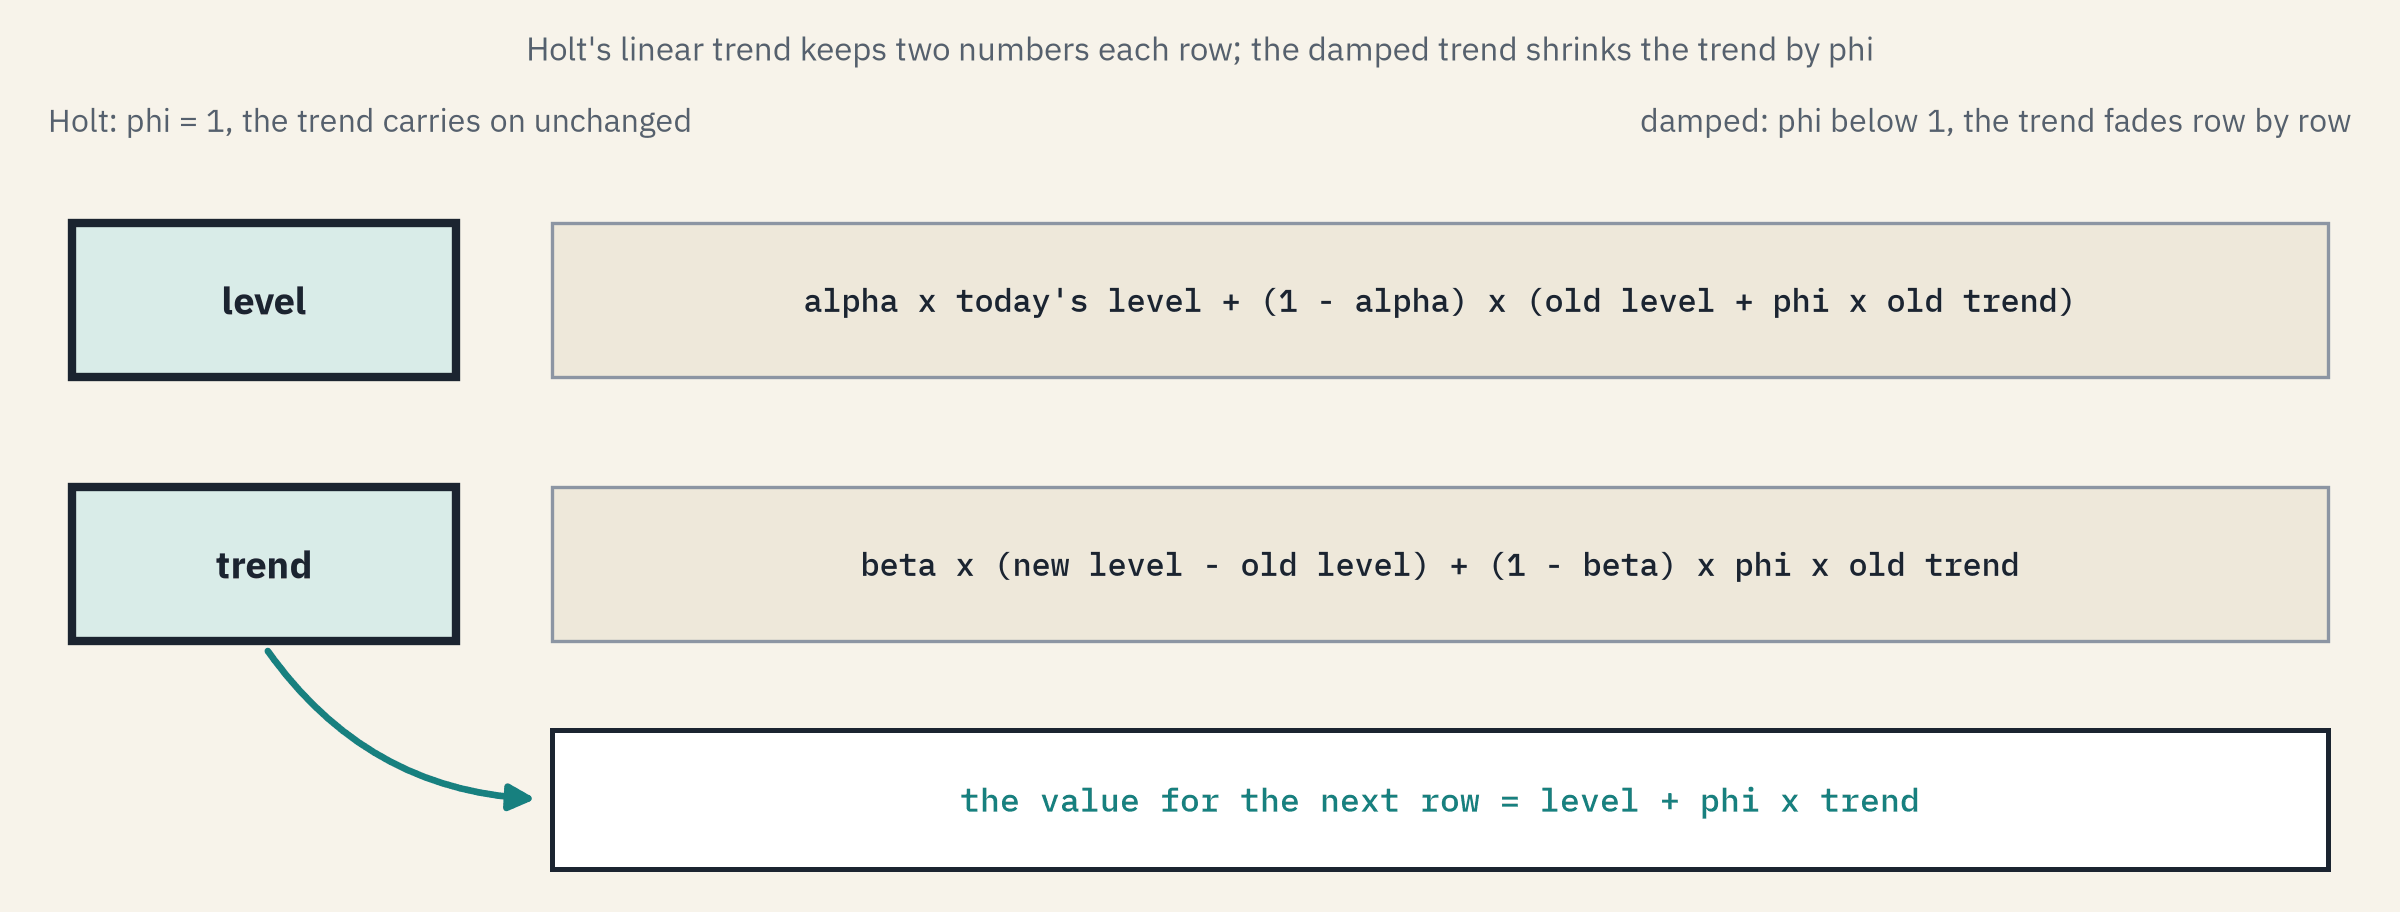)

**Holt's linear trend** keeps two numbers: a level, and a **trend**, the change per row.
**beta** is the trend's alpha, the weight a new row's change gets in the trend.
The **damped trend** multiplies the trend by **phi**, below 1, at every row, so it fades.
In `ExponentialSmoothing`, `trend="add"` adds the trend and `damped_trend=True` damps it.

**Predict 2**

Q. Holt's trend on the same 741 levels of the 10 Yr: what beta does least squares give it? Write down a number between 0 and 1.

## Three Smoothers on Fold 1

In [20]:
# the three smoothers on fold 1's training levels: no trend, Holt's trend, the damped trend
values = fold1_levels.to_numpy()
fits = {"simple": simple,
        "Holt": ExponentialSmoothing(values, trend="add", initialization_method="estimated").fit(),
        "damped": ExponentialSmoothing(values, trend="add", damped_trend=True, initialization_method="estimated").fit()}

# each fit's weights, its starting trend in bp a row, and its AIC and BIC
pd.DataFrame({name: {"alpha": fit.params["smoothing_level"], "beta": fit.params["smoothing_trend"],
                     "phi": fit.params["damping_trend"], "starting trend": fit.params["initial_trend"],
                     "AIC": fit.aic, "BIC": fit.bic} for name, fit in fits.items()}).T

,alpha,beta,phi,starting trend,AIC,BIC
simple,0.9364,NaN,NaN,NaN,2242.1390,2251.3550
Holt,0.9363,0.0000,NaN,0.0319,2246.0970,2264.5291
damped,0.9314,0.0000,0.8000,-9.2601,2242.8093,2265.8493


### Interpretation of Beta and Phi

Beta is 0 in both: a new row's change never enters the trend, so Holt's trend stays at its start, 0.0319 bp a row, a constant drift, like Day 2's drift rule inside a smoother.

The damped trend's phi sits at 0.8, the lowest value statsmodels allows by default, so its trend shrinks by a fifth every row.

Alpha hardly moves, and the lowest AIC and the lowest BIC both belong to simple smoothing.

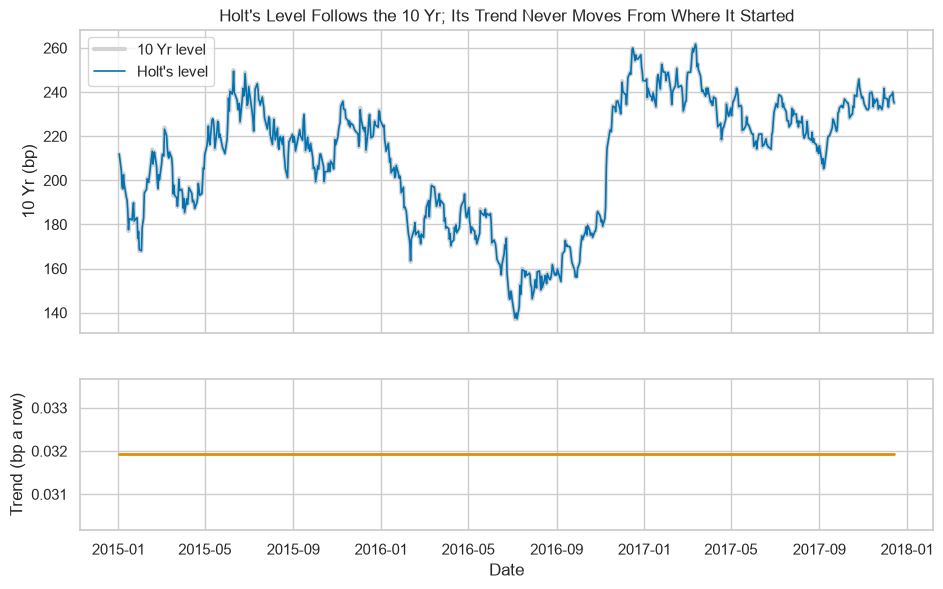

In [21]:
# Holt's two numbers on each of fold 1's training dates: the level, and the trend in bp a row
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[2, 1])
top.plot(fold1_levels.index, values, color="lightgray", linewidth=3, label="10 Yr level")
top.plot(fold1_levels.index, fits["Holt"].level, color="C0", linewidth=1.2, label="Holt's level")
bottom.plot(fold1_levels.index, fits["Holt"].trend, color="C1", linewidth=2)
top.set(ylabel="10 Yr (bp)", title="Holt's Level Follows the 10 Yr; Its Trend Never Moves From Where It Started")
bottom.set(ylabel="Trend (bp a row)", xlabel="Date")
top.legend(loc="upper left")
plt.show()

**The trend term has nothing to learn on a daily level. AIC reads only the training rows, so we still score all three on the folds.**

# Walk-Forward Scoring

## Five Folds, Fitted Once Each

Each fold fits a smoother on its training levels, then runs the same smoother on through its test dates with every weight held.
`initialization_method="known"` takes the fitted starting values, and `.fit(..., optimized=False)` keeps the fitted weights.
Its `.fittedvalues` are one-step values: each reads only the rows before its date.

In [22]:
def walk_smoother(name, trend=None, damped=False):
    """A smoother's MAE in bp on each fold's test dates, fitted on that fold's training levels."""
    maes = []
    for fit_rows, test_rows in folds:
        train, test = changes.index[fit_rows], changes.index[test_rows]
        p = ExponentialSmoothing(levels.loc[:train[-1], name].to_numpy(), trend=trend, damped_trend=damped,
                                 initialization_method="estimated").fit().params
        # run on to the last test date with the weights held (simple smoothing has no starting trend)
        held = ExponentialSmoothing(levels.loc[:test[-1], name].to_numpy(), trend=trend, damped_trend=damped,
                                    initialization_method="known", initial_level=p["initial_level"],
                                    initial_trend=p["initial_trend"] if trend else None)
        values = held.fit(smoothing_level=p["smoothing_level"], smoothing_trend=p["smoothing_trend"],
                          damping_trend=p["damping_trend"], optimized=False).fittedvalues
        before = levels.loc[:test[-1], name].shift(1).to_numpy()
        maes.append(mean_absolute_error(changes.loc[test, name], values[-252:] - before[-252:]))
    return maes

In [23]:
# the three smoothers on the five series: one row per series, model and fold, with the bar beside it
rows = []
for name in levels.columns:
    for model, trend, damped in [("simple", None, False), ("Holt", "add", False), ("damped", "add", True)]:
        for fold, mae in enumerate(walk_smoother(name, trend, damped), start=1):
            rows.append({"series": name, "model": model, "fold": fold, "MAE": mae, "last value": bar.loc[name, f"fold {fold}"]})
print(len(rows), "fold scores")

75 fold scores


Day 5's AR(1) on the changes joins them, walked forward as Day 5 walked it: fitted once a fold, then `.append()` runs it on through the test dates with its coefficients held.

In [24]:
# Day 5's AR(1) on each fold, its one-step values on the test dates from .append() and .predict()
converged = []
for name in levels.columns:
    for fold, (fit_rows, test_rows) in enumerate(folds, start=1):
        ar = ARIMA(changes[name].iloc[fit_rows].to_numpy(), order=(1, 0, 0), trend="c").fit(method_kwargs={"warn_convergence": False})
        values = ar.append(changes[name].iloc[test_rows].to_numpy(), refit=False).predict(start=len(fit_rows), end=len(fit_rows) + 251)
        converged.append(ar.mle_retvals["converged"])
        rows.append({"series": name, "model": "AR(1)", "fold": fold, "MAE": mean_absolute_error(changes[name].iloc[test_rows], values),
                     "last value": bar.loc[name, f"fold {fold}"]})
print("converged", sum(converged), "of", len(converged), "fits")

converged 25 of 25 fits


## The Table Beside the Bar

In [25]:
# each model's MASE: its average fold MAE over the last value's
scores = pd.DataFrame(rows)
mase = scores.groupby(["series", "model"], sort=False)["MAE"].mean().unstack() / bar[["average"]].values
mase

model,simple,Holt,damped,AR(1)
series,,,,
2 Yr,1.0073,1.0070,1.0056,1.0090
10 Yr,1.0024,1.0034,1.0027,1.0035
2s10s,1.0042,1.0051,1.0043,1.0049
IG,1.0043,1.0047,1.0044,1.0046
HY,1.0034,1.0035,1.0035,1.0042


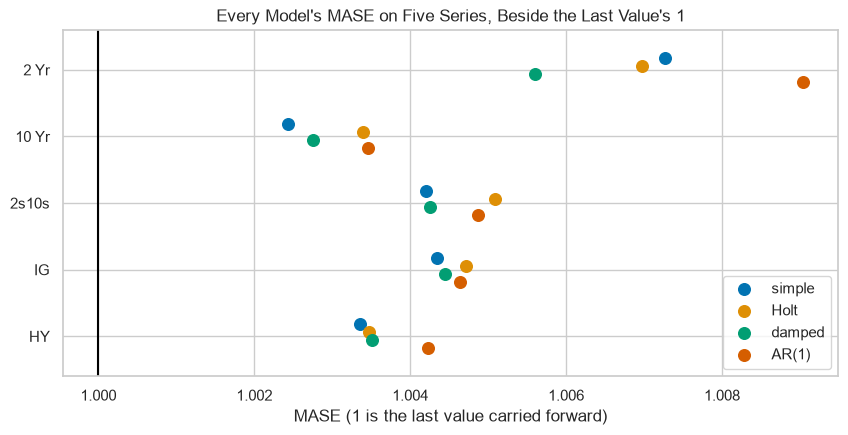

In [26]:
# MASE by series and model as dots, 1 marked: the last value
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, model in enumerate(mase.columns):
    ax.scatter(mase[model], np.arange(5) + (k - 1.5) * 0.12, s=70, label=model, zorder=3)
ax.axvline(1, color="black", linewidth=1.5)
ax.set(yticks=range(5), yticklabels=mase.index, ylim=(4.6, -0.6), xlabel="MASE (1 is the last value carried forward)")
ax.set_title("Every Model's MASE on Five Series, Beside the Last Value's 1")
ax.legend(loc="lower right")
plt.show()

All 20 MASEs sit above 1, from 1.0024 (simple smoothing, 10 Yr) to 1.0090 (the AR(1), 2 Yr).

Simple smoothing has the lowest MASE of the four on the 10 Yr, the 2s10s, IG and HY; the damped trend on the 2 Yr.

## Fold by Fold

In [27]:
# simple smoothing's fold MAE less the last value's, per series and fold, in bp
simple_gaps = scores[scores["model"] == "simple"].assign(gap=lambda s: s["MAE"] - s["last value"])
print("Folds where simple smoothing is closer:", (simple_gaps["gap"] < 0).sum(), "of", len(simple_gaps))
simple_gaps.pivot(index="series", columns="fold", values="gap").loc[levels.columns]

Folds where simple smoothing is closer: 6 of 25


fold,1,2,3,4,5
2 Yr,0.0489,-0.0273,0.0607,-0.0023,0.0291
10 Yr,0.0078,0.0016,0.0231,-0.0001,0.0146
2s10s,0.0171,0.0188,0.0010,0.0062,0.0109
IG,0.0028,0.0090,-0.0063,0.0118,0.0025
HY,0.0064,0.0249,-0.0031,0.0378,-0.0000


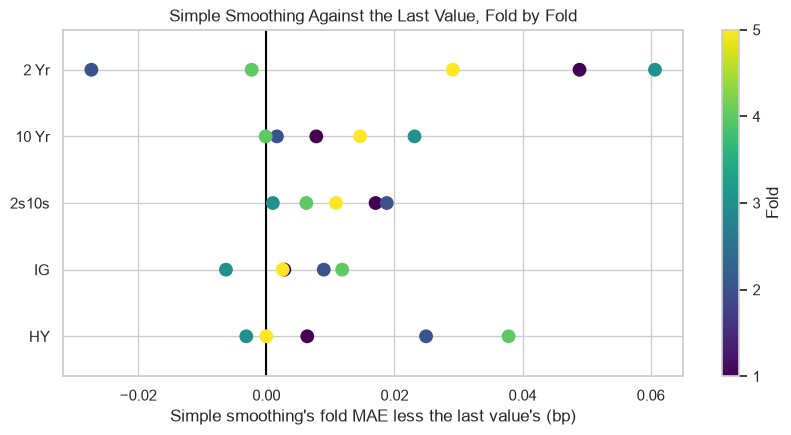

In [28]:
# each fold's gap as a dot, one row per series, coloured by fold, zero marked
fig, ax = plt.subplots(figsize=(10, 4.5))
rows_of = {name: k for k, name in enumerate(levels.columns)}
dots = ax.scatter(simple_gaps["gap"], simple_gaps["series"].map(rows_of), c=simple_gaps["fold"], cmap="viridis", s=80, zorder=3)
fig.colorbar(dots, ax=ax, label="Fold", ticks=range(1, 6))
ax.axvline(0, color="black", linewidth=1.5)
ax.set(yticks=range(5), yticklabels=levels.columns, ylim=(4.6, -0.6), xlabel="Simple smoothing's fold MAE less the last value's (bp)")
ax.set_title("Simple Smoothing Against the Last Value, Fold by Fold")
plt.show()

Simple smoothing is closer in 6 of 25 folds, and the 10 Yr's one win is 0.0001 bp.

Every gap is under 0.07 bp, while the folds disagree by 0.47 to 4.58 bp (the bar table).

**By Day 2's rule no smoother beats the last value on any of the five series: every gap is far inside the folds' disagreement, and most go the wrong way.**

# Choosing Alpha by the Folds

## A Fixed Alpha as a Rule

A fixed alpha needs no fit: its one-step value is the EWMA through the row before, so it scores every fold at once.

In [29]:
# for each fixed alpha: the MAE in bp over the 1,260 scored dates, which is the five folds' average (Day 2)
scored = changes.index[folds[0][1][0]:]
grid = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0]
fixed_mae, fixed_size = {}, {}
for a in grid:
    fitted = (levels.ewm(alpha=a, adjust=False).mean().shift(1) - levels.shift(1)).loc[scored]
    fixed_mae[a] = (fitted - changes.loc[scored]).abs().mean()
    fixed_size[a] = fitted.abs().mean()
fixed_gap = pd.DataFrame(fixed_mae).T - bar["average"]
fixed_gap

,2 Yr,10 Yr,2s10s,IG,HY
0.0500,10.5236,9.9216,5.6040,1.9000,7.8871
0.1000,5.0083,5.3508,3.0715,1.0675,4.5362
0.2000,2.1982,2.4799,1.4913,0.5195,2.3715
0.3000,1.2624,1.4244,0.8848,0.3016,1.4521
0.5000,0.4830,0.5405,0.3615,0.1190,0.5914
0.7000,0.1548,0.1630,0.1154,0.0394,0.1995
0.9000,0.0214,0.0227,0.0196,0.0047,0.0271
1.0000,0.0000,0.0000,0.0000,0.0000,0.0000


The table holds each alpha's MAE less the bar's, in bp: every number is at or above 0.

The best fixed alpha is 1 on all five series, and alpha 1 is the last value itself.

Alpha 0.5 already costs 0.12 bp (IG) to 0.59 bp (HY) a date.

## Smoothness Against Closeness

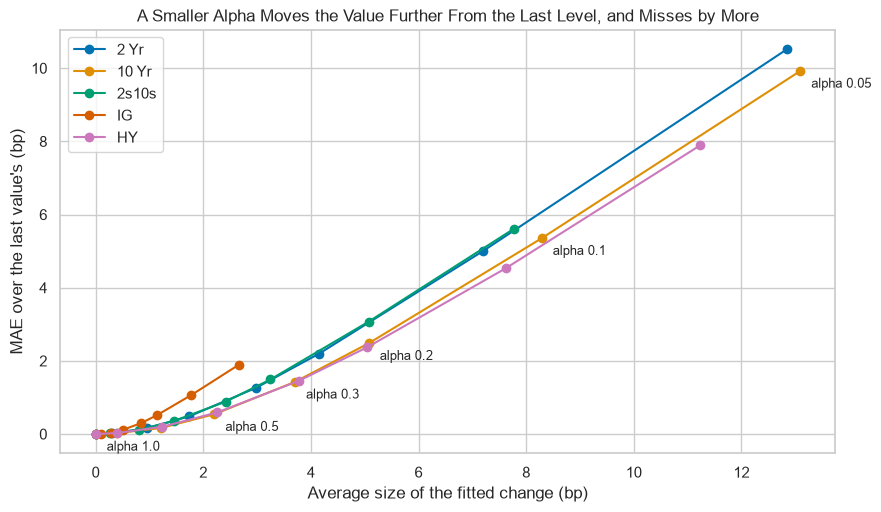

In [30]:
# per series: the average size of the fitted change against the MAE over the bar, one dot per alpha
fixed_size = pd.DataFrame(fixed_size).T
fig, ax = plt.subplots(figsize=(10, 5.5))
for name in levels.columns:
    ax.plot(fixed_size[name], fixed_gap[name], marker="o", label=name)
for a in [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]:
    ax.annotate(f"alpha {a}", (fixed_size.loc[a, "10 Yr"], fixed_gap.loc[a, "10 Yr"]), xytext=(8, -12), textcoords="offset points", fontsize=9)
ax.set(xlabel="Average size of the fitted change (bp)", ylabel="MAE over the last value's (bp)")
ax.set_title("A Smaller Alpha Moves the Value Further From the Last Level, and Misses by More")
ax.legend(loc="upper left")
plt.show()

Every series climbs the same way: the further alpha moves the value from the last level, the more it misses.

**On these levels every bit of smoothing moves the value away from the next level. The level's change has almost no memory for an average to keep.**

# Smoothing the Size of a Change

Day 4 found that the sign of a day's change remembers little and its size remembers a lot.
The size is where an average has something to keep.

RiskMetrics, the risk method J.P.

Morgan published with Reuters, runs the EWMA on each day's squared return and names the weight on the old average **lambda**, so alpha = 1 - lambda.

The square root of that average is an **EWMA volatility**, in bp a day.

Its Technical Document chooses lambda = 0.94 for its daily data set (J.P.

Morgan and Reuters, RiskMetrics Technical Document, fourth edition, December 1996, section 5.3.2, p.

97, [the document at MSCI](https://www.msci.com/documents/10199/5915b101-4206-4ba0-aee2-3449d5c7e95a)).

Here the same line runs on the squared change in bp and describes the size of the file's past days, never a risk limit.

## RiskMetrics Volatility of the 10 Yr

`.expanding().mean()` averages every row up to each date with the same weight, with no decay at all.

In [31]:
# the EWMA of the squared change at lambda 0.94, and the equal-weight average, each square-rooted into bp a day
LAMBDA = 0.94
squares = changes["10 Yr"] ** 2
riskmetrics = np.sqrt(squares.ewm(alpha=1 - LAMBDA, adjust=False).mean())
equal = np.sqrt(squares.expanding().mean())
print("Half-life at lambda 0.94:", round(np.log(0.5) / np.log(LAMBDA), 1), "rows")
print("Through 2022-12-30: RiskMetrics", round(riskmetrics.iloc[-1], 2), "bp a day | equal weights", round(equal.iloc[-1], 2), "bp a day")

Half-life at lambda 0.94: 11.2 rows
Through 2022-12-30: RiskMetrics 7.49 bp a day | equal weights 5.03 bp a day


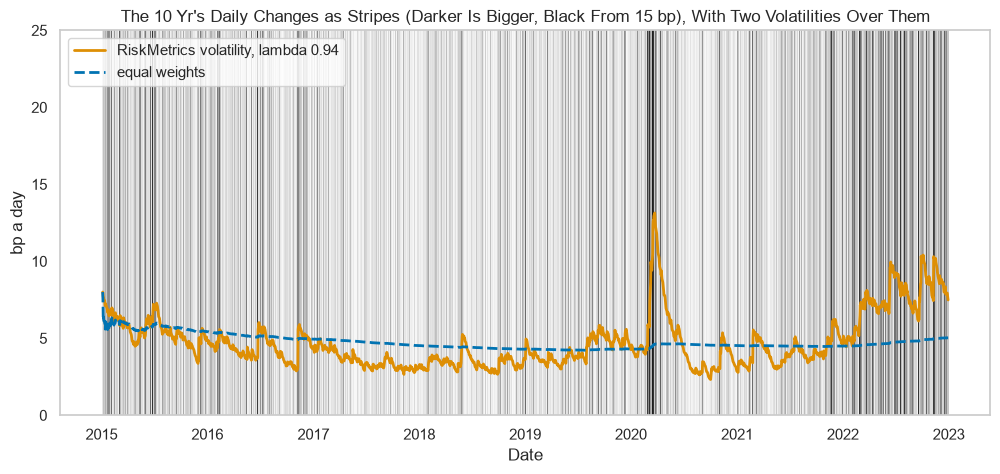

In [32]:
# one stripe per date, shaded by the size of its change, with the two volatilities over them
size = changes["10 Yr"].abs()
fig, ax = plt.subplots(figsize=(12, 5))
ax.vlines(size.index, 0, 25, colors=plt.cm.Greys(np.minimum(size / 15, 1) * 0.85 + 0.05), linewidth=1.2)
ax.plot(riskmetrics, color="C1", linewidth=2, label="RiskMetrics volatility, lambda 0.94")
ax.plot(equal, color="C0", linewidth=2, linestyle="--", label="equal weights")
ax.grid(False)
ax.set(ylim=(0, 25), xlabel="Date", ylabel="bp a day")
ax.set_title("The 10 Yr's Daily Changes as Stripes (Darker Is Bigger, Black From 15 bp), With Two Volatilities Over Them")
ax.legend(loc="upper left")
plt.show()

The dark stripes gather in March 2020 and through 2022, and the RiskMetrics line rises with each cluster and falls back within weeks.

The equal-weight line barely moves after its first year: by 2022 it averages seven years of days.

Through the last date, RiskMetrics reads 7.49 bp a day and equal weights 5.03.

**Predict 3**

A band of plus and minus 2 volatilities around zero, each date's volatility read through the row before, holds most daily changes.

Q. For each year from 2015 to 2022, sketch how many dates fall outside the band, once with equal weights and once with lambda 0.94.

## Two Bands, Two Pictures

In [33]:
# each date's band from the volatility through the row before, after 20 dates to warm the averages up
bands = pd.DataFrame({"change": changes["10 Yr"], "equal": equal.shift(1), "RiskMetrics": riskmetrics.shift(1)}).iloc[20:]
outside = pd.DataFrame({k: bands["change"].abs() > 2 * bands[k] for k in ["equal", "RiskMetrics"]})
print(len(bands), "dates from", bands.index[0].date(), "| outside:", outside.sum().to_dict())
print("Share outside (percent):", (outside.mean() * 100).round(2).to_dict())

1980 dates from 2015-02-03 | outside: {'equal': 112, 'RiskMetrics': 100}
Share outside (percent): {'equal': 5.66, 'RiskMetrics': 5.05}


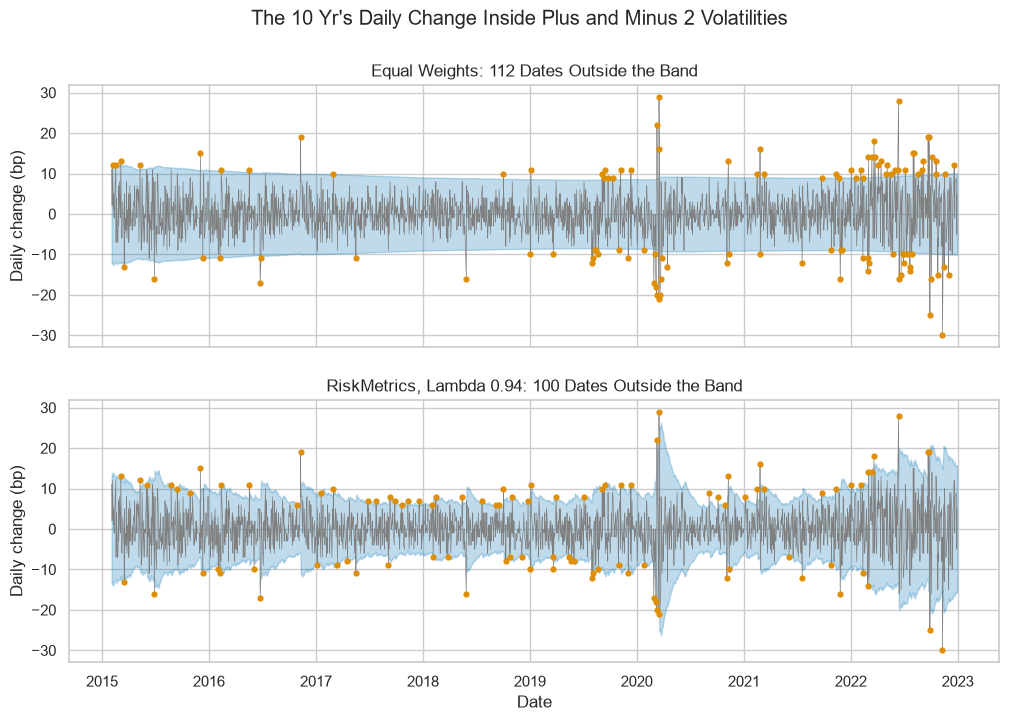

In [34]:
# the change with each band shaded, the dates outside dotted
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, k, name in zip(axes, ["equal", "RiskMetrics"], ["Equal Weights", "RiskMetrics, Lambda 0.94"]):
    ax.plot(bands["change"], color="gray", linewidth=0.5)
    ax.fill_between(bands.index, -2 * bands[k], 2 * bands[k], color="C0", alpha=0.25)
    ax.scatter(bands.index[outside[k]], bands["change"][outside[k]], s=12, color="C1", zorder=3)
    ax.set(ylabel="Daily change (bp)", title=f"{name}: {outside[k].sum()} Dates Outside the Band")
axes[1].set_xlabel("Date")
fig.suptitle("The 10 Yr's Daily Change Inside Plus and Minus 2 Volatilities")
plt.show()

### Dates Outside by Year

In [35]:
# dates outside each band by year, and how spread the change is in volatility units each year
by_year = outside.groupby(outside.index.year).sum()
units = pd.DataFrame({k: bands["change"] / bands[k] for k in ["equal", "RiskMetrics"]})
print("Spread of the change in volatility units, by year:", units.groupby(units.index.year).std().agg(["min", "max"]).round(2).to_dict())
by_year

Spread of the change in volatility units, by year: {'equal': {'min': 0.74, 'max': 1.64}, 'RiskMetrics': {'min': 1.01, 'max': 1.07}}


,equal,RiskMetrics
date,,
2015,8,10
2016,6,8
2017,2,14
2018,2,15
2019,17,18
2020,16,13
2021,12,10
2022,49,12


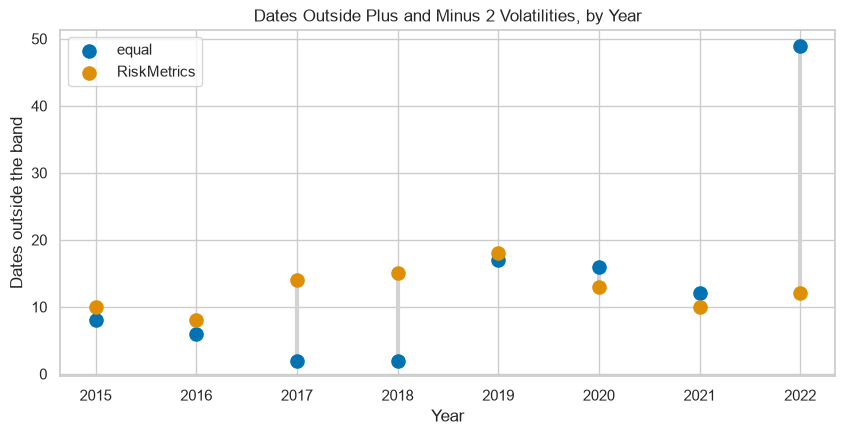

In [36]:
# dates outside by year, one dot per band, joined
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.vlines(by_year.index, by_year.min(axis=1), by_year.max(axis=1), color="lightgray", linewidth=3)
for k, colour in [("equal", "C0"), ("RiskMetrics", "C1")]:
    ax.scatter(by_year.index, by_year[k], s=90, color=colour, label=k, zorder=3)
ax.set(xlabel="Year", ylabel="Dates outside the band", xticks=by_year.index)
ax.set_title("Dates Outside Plus and Minus 2 Volatilities, by Year")
ax.legend(loc="upper left")
plt.show()

Over all dates the two bands look alike: 112 dates outside for equal weights, 100 for RiskMetrics, about 5 percent each.

By year they part: equal weights put 2 dates outside in 2017 and 49 in 2022, RiskMetrics between 8 and 18 every year.

In volatility units the change's spread runs from 0.74 to 1.64 by year with equal weights, and from 1.01 to 1.07 with RiskMetrics.

**Equal weights describe 2017 as calm and 2022 as rare; a decaying weight describes each year by its own size.**

# Scoring the Size Walk-Forward

The bands describe the size; scoring asks whether a value for it from the rows before gets closer than a rule with no model.
The target is the size of the change, `abs()`, in bp.
The same EWMA runs on the size itself, so every score is in bp of size.

## Two Rules for the Size

In [37]:
# two rules for the size of each 10 Yr change: the training mean, and the last size carried forward
size_rows = []
for fold, (fit_rows, test_rows) in enumerate(folds, start=1):
    train, test = changes.index[fit_rows], changes.index[test_rows]
    size_rows.append({"fold": fold, "training mean": mean_absolute_error(size[test], [size[train].mean()] * len(test)),
                      "last value": mean_absolute_error(size[test], size.shift(1)[test])})
size_scores = pd.DataFrame(size_rows).set_index("fold")
size_scores.mean()

training mean   2.4881
last value      3.1714
dtype: float64

The training mean misses the size by 2.488 bp a date, the last size by 3.171: a single day's size is a noisy guide to the next.

**Predict 4**

Q. The EWMA of the size at lambda 0.94, through the row before each date: what is its MAE over the five folds, in bp? Write down a number.

## The Size on the Five Folds

In [38]:
# the EWMA of the size through the row before, scored on each fold's test dates
smoothed_size = size.ewm(alpha=1 - LAMBDA, adjust=False).mean().shift(1)
size_scores["lambda 0.94"] = [mean_absolute_error(size.iloc[test], smoothed_size.iloc[test]) for train, test in folds]
print("Averages:", size_scores.mean().round(3).to_dict())
print("Folds closer than the training mean:", (size_scores["lambda 0.94"] < size_scores["training mean"]).sum(), "of 5")
print("The training mean's folds disagree by", round(size_scores["training mean"].max() - size_scores["training mean"].min(), 3), "bp")
size_scores

Averages: {'training mean': 2.488, 'last value': 3.171, 'lambda 0.94': 2.359}
Folds closer than the training mean: 4 of 5
The training mean's folds disagree by 1.899 bp


,training mean,last value,lambda 0.94
fold,,,
1,1.9156,2.3651,1.7058
2,2.0978,2.7540,2.1339
3,2.5663,2.9325,2.4542
4,2.0468,2.8294,2.0413
5,3.8141,4.9762,3.4619


In [39]:
# the same on all five series: lambda 0.94's average MAE over the training mean's
ratios = {}
for name in levels.columns:
    s = changes[name].abs()
    smoothed = s.ewm(alpha=1 - LAMBDA, adjust=False).mean().shift(1)
    ewma_mae = np.mean([mean_absolute_error(s.iloc[test], smoothed.iloc[test]) for train, test in folds])
    mean_mae = np.mean([mean_absolute_error(s.iloc[test], [s.iloc[train].mean()] * len(test)) for train, test in folds])
    ratios[name] = round(float(ewma_mae / mean_mae), 3)
print(ratios)

{'2 Yr': 0.889, '10 Yr': 0.948, '2s10s': 0.98, 'IG': 0.992, 'HY': 0.966}


### Interpretation of the Size Scores

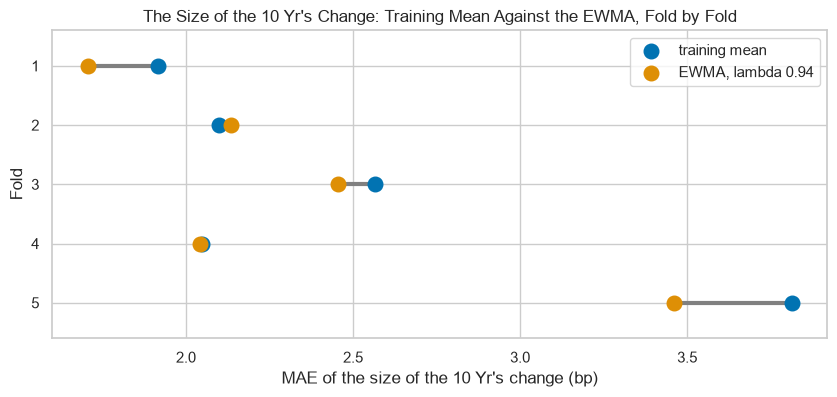

In [40]:
# per fold: the training mean's MAE joined to lambda 0.94's
fig, ax = plt.subplots(figsize=(10, 4))
ax.hlines(size_scores.index, size_scores["training mean"], size_scores["lambda 0.94"], color="gray", linewidth=3)
ax.scatter(size_scores["training mean"], size_scores.index, s=110, color="C0", label="training mean", zorder=3)
ax.scatter(size_scores["lambda 0.94"], size_scores.index, s=110, color="C1", label="EWMA, lambda 0.94", zorder=3)
ax.set(yticks=size_scores.index, ylim=(5.6, 0.4), xlabel="MAE of the size of the 10 Yr's change (bp)", ylabel="Fold")
ax.set_title("The Size of the 10 Yr's Change: Training Mean Against the EWMA, Fold by Fold")
ax.legend(loc="upper right")
plt.show()

The EWMA of the size misses by 2.359 bp a date, the training mean by 2.488 and the last size by 3.171.

It is closer than the training mean in 4 of 5 folds; fold 2 is the exception, 2.134 against 2.098.

Its average MAE sits below the training mean's on every series, from 0.889 of it (2 Yr) to 0.992 (IG).

By Day 2's rule the gap on the 10 Yr, 0.13 bp (2.488 less 2.359), sits well inside the 1.899 bp the folds disagree by, so by that rule it has not beaten a constant.

The lambda stays at the published 0.94: a lambda tuned on these folds would be chosen after seeing them.

**On the size a smoother edges ahead of a constant in 4 of 5 folds, by less than the folds disagree. Day 7 fits a model of the size, GARCH.**

# Insights and Conclusion

![One line, new average = alpha x today + (1 - alpha) x old average, does two jobs. On the level: least squares puts alpha near 1, the value is nearly the last level, and the MASE is above 1 on all five series, so carry the last value. On the size of a change: lambda 0.94, alpha 0.06, a half-life of 11.2 rows, a band that keeps up with the big days, and closer than a constant in 4 of 5 folds, so describe the size, and Day 7 models it](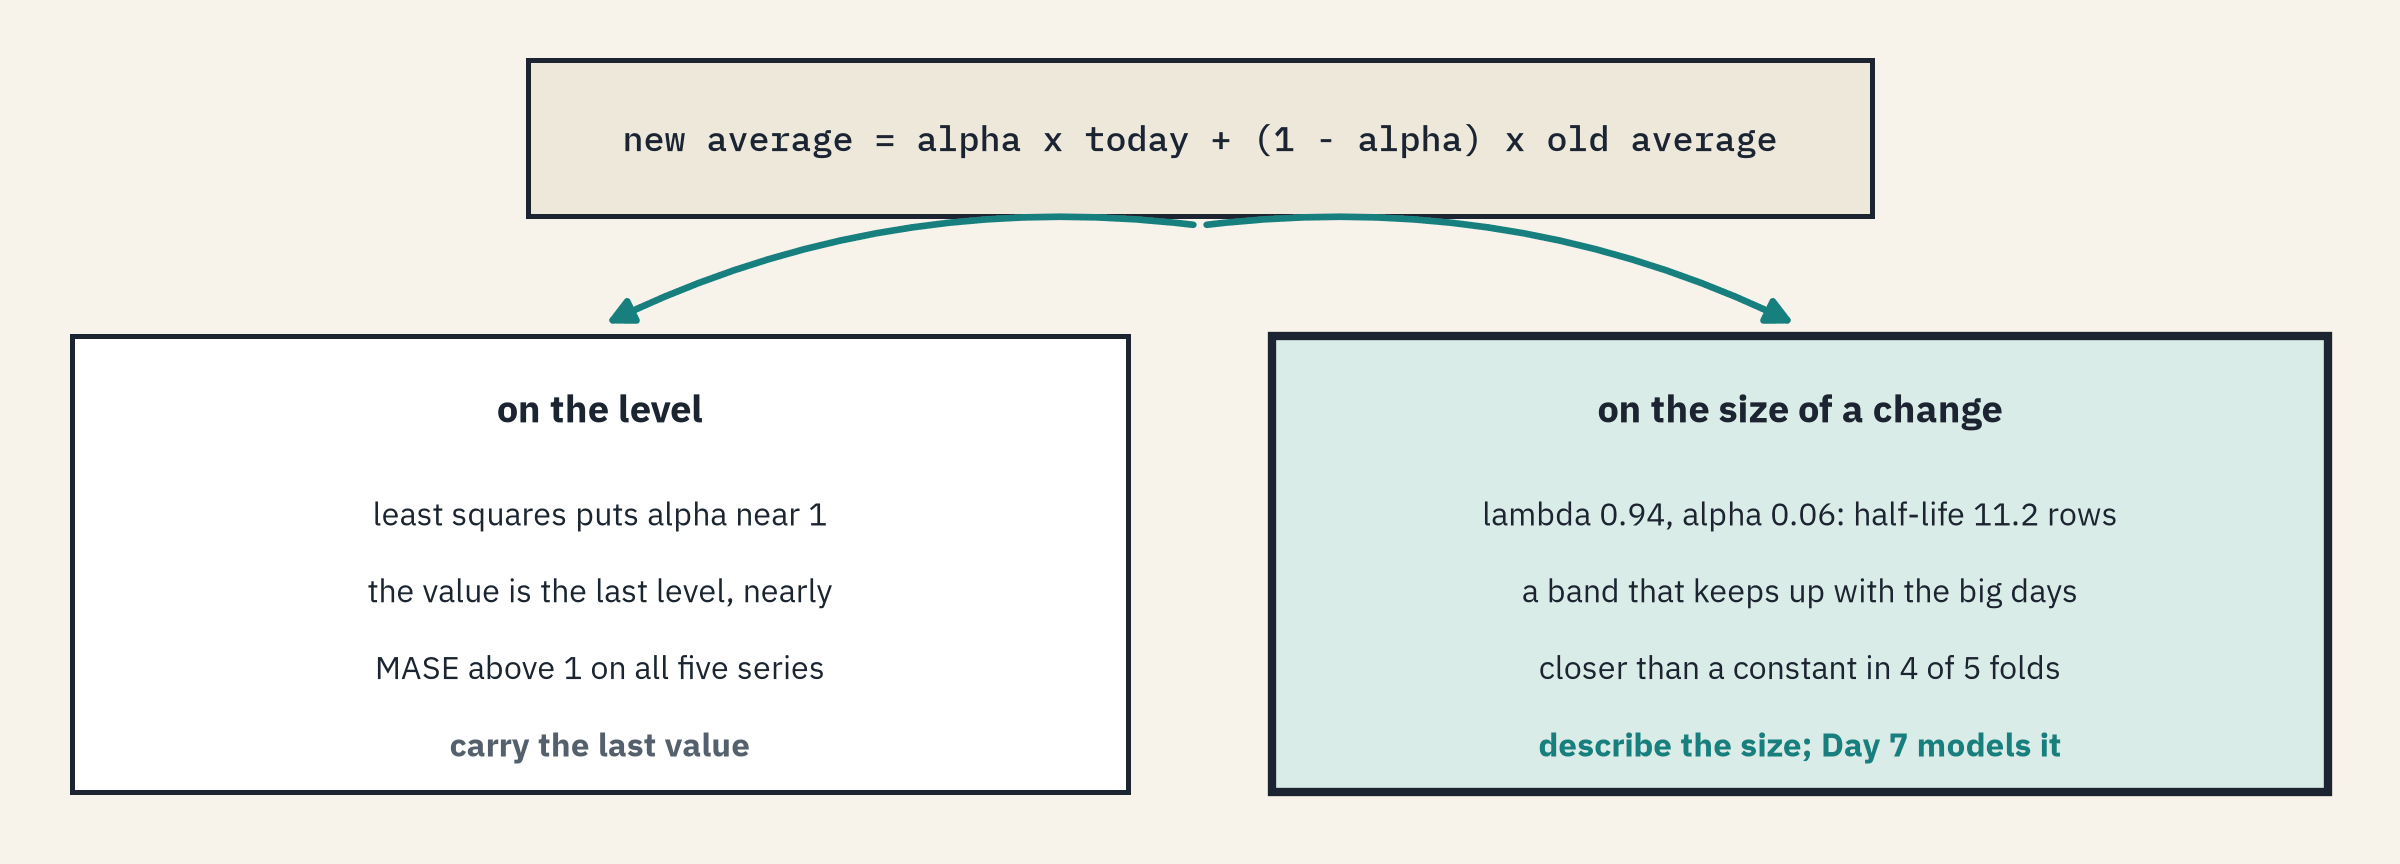)

On fold 1 the sum of squared misses is lowest between alpha 0.86 and 0.94 on all five series, so simple smoothing's value is nearly the last level.

Holt's beta is 0 and the damped trend's phi sits on its bound: a daily level gives a trend nothing to learn.

Every smoother's MASE runs from 1.0024 to 1.0073, inside the folds' disagreement, and a fixed alpha scores best at 1, the last value itself.

On the size of a change the same line, at RiskMetrics' lambda 0.94, describes each year by its own size and edges ahead of a constant.

**Carry the level forward; smooth the size to describe it.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Write an EWMA as a loop and with `.ewm(alpha=..., adjust=False).mean()`, and read alpha as a half-life.
* Fit simple smoothing, Holt's trend and the damped trend with `ExponentialSmoothing`, and read alpha, beta and phi.
* Turn a smoother into one-step values with `.shift(1)`, or with a refit whose weights are held, and pass the cut test.
* Score smoothers walk-forward with MASE beside the last value and an AR(1).
* Build an EWMA volatility of daily changes, draw its band, and score the smoothed size of a change.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [41]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Alpha on the IG Spread**

Q. Fit simple smoothing on IG's levels up to fold 1's last training date, as for the 10 Yr. Store its alpha in `ex1_alpha`.

In [42]:
# simple smoothing on IG's levels up to fold 1's last training date
ig_simple = ExponentialSmoothing(levels.loc[:fold1_levels.index[-1], "IG"].to_numpy(), initialization_method="estimated").fit()
ex1_alpha = ig_simple.params["smoothing_level"]
print(ex1_alpha)

0.888599176501727


In [43]:
check("Exercise 1 IG's alpha on fold 1", ex1_alpha, 0.888599176501727)

Exercise 1 IG's alpha on fold 1: correct


### Exercise 2

**The Band on the HY Spread**

Q. Build the RiskMetrics volatility (lambda 0.94) of HY's daily change, read each date's volatility through the row before, skip the first 20 dates as above, and count the dates whose change lies outside plus and minus 2 volatilities. Store the count in `ex2_outside`.

In [44]:
# HY's RiskMetrics volatility through the row before, and the dates outside its band after the first 20
hy = changes["HY"]
hy_volatility = np.sqrt((hy ** 2).ewm(alpha=1 - LAMBDA, adjust=False).mean()).shift(1)
ex2_outside = int((hy.abs() > 2 * hy_volatility).iloc[20:].sum())
print(ex2_outside, "of", len(hy) - 20, "dates")

112 of 1980 dates


In [45]:
check("Exercise 2 HY dates outside the band", ex2_outside, 112)

Exercise 2 HY dates outside the band: correct


### Exercise 3

**A Function for the Half-Life**

Q. Write `weight_half_life(alpha)`, which returns the number of rows after which an EWMA's weight has fallen to half the newest row's. Store `weight_half_life(0.06)` in `ex3_rows`.

In [46]:
# the k at which (1 - alpha)^k falls to one half
def weight_half_life(alpha):
    return np.log(0.5) / np.log(1 - alpha)

ex3_rows = weight_half_life(0.06)
print(ex3_rows)

11.202305583621158


In [47]:
check("Exercise 3 the half-life at alpha 0.06", ex3_rows, 11.202305583621158)

Exercise 3 the half-life at alpha 0.06: correct


### Exercise 4

**The 2 Yr's Volatility**

Q. What is the RiskMetrics volatility (lambda 0.94) of the 2 Yr's daily change through the last development date, in bp a day? Store it in `ex4_vol`.

In [48]:
# the EWMA of the 2 Yr's squared change at lambda 0.94, square-rooted, on the last development date
two = changes["2 Yr"]
ex4_vol = np.sqrt((two ** 2).ewm(alpha=1 - LAMBDA, adjust=False).mean()).iloc[-1]
print(ex4_vol)

6.8210583455525216


In [49]:
check("Exercise 4 the 2 Yr's volatility on 2022-12-30", ex4_vol, 6.8210583455525216)

Exercise 4 the 2 Yr's volatility on 2022-12-30: correct


### Exercise 5: AI check

**The Average That Saw Its Own Date**

You asked an AI assistant for each date's value from an EWMA, to score a smoother on a random walk.
This came back, and its miss is smaller than the last value's.
Test it, then find the one bug.

In [50]:
# a random walk of 300 levels in bp from the seeded generator, steps of about 2 bp
rng = np.random.default_rng(SEED)
walk = pd.Series(200 + np.cumsum(rng.normal(0, 2, 300)))

In [51]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def smoothed_value(levels_bp, alpha=0.3):
    # the value for each date: an EWMA of the levels, to score against that date's level
    return levels_bp.ewm(alpha=alpha, adjust=False).mean()

print("Its miss:", round((walk - smoothed_value(walk)).abs().mean(), 3), "bp | the last value's:",
      round(walk.diff().abs().mean(), 3), "bp")

Its miss: 1.409 bp | the last value's: 1.469 bp


In [52]:
# the test: move the last level by 100 bp; the value for that date must not move
bumped = walk.copy()
bumped.iloc[-1] = bumped.iloc[-1] + 100
assert smoothed_value(bumped).iloc[-1] == smoothed_value(walk).iloc[-1], "the value for a date moved with that date's own level"

AssertionError: the value for a date moved with that date's own level

Q. Fix the function, and store the fixed function's average miss on the walk, in bp, in `ex5_miss`.

In [53]:
# the fix: shift(1), so the value for a date is the average through the row before
def smoothed_value(levels_bp, alpha=0.3):
    return levels_bp.ewm(alpha=alpha, adjust=False).mean().shift(1)

assert smoothed_value(bumped).iloc[-1] == smoothed_value(walk).iloc[-1]
ex5_miss = (walk - smoothed_value(walk)).abs().mean()
print(ex5_miss)

2.020064387170852


The assistant's average included each date's own level, so part of every miss was the date scoring itself.
Shifted, the smoother misses the walk by more than the last value does, as every smoother of a level did today.

In [54]:
check("Exercise 5 the honest miss", ex5_miss, 2.020064387170852)

Exercise 5 the honest miss: correct


## Congratulations!

You wrote the oldest smoother in time series as a three-line loop and matched pandas to the last digit.
You watched least squares push alpha toward 1, found Holt's trend with nothing to learn, and scored every smoother walk-forward beside the last value and Day 5's AR(1).
Then you turned the same line on the size of a change and drew a band that describes each year by its own size.
That is the honest work of a quant desk: try the model, score it fairly, and say what it does not do.
In Day 7 you fit GARCH, a model of the size itself.

[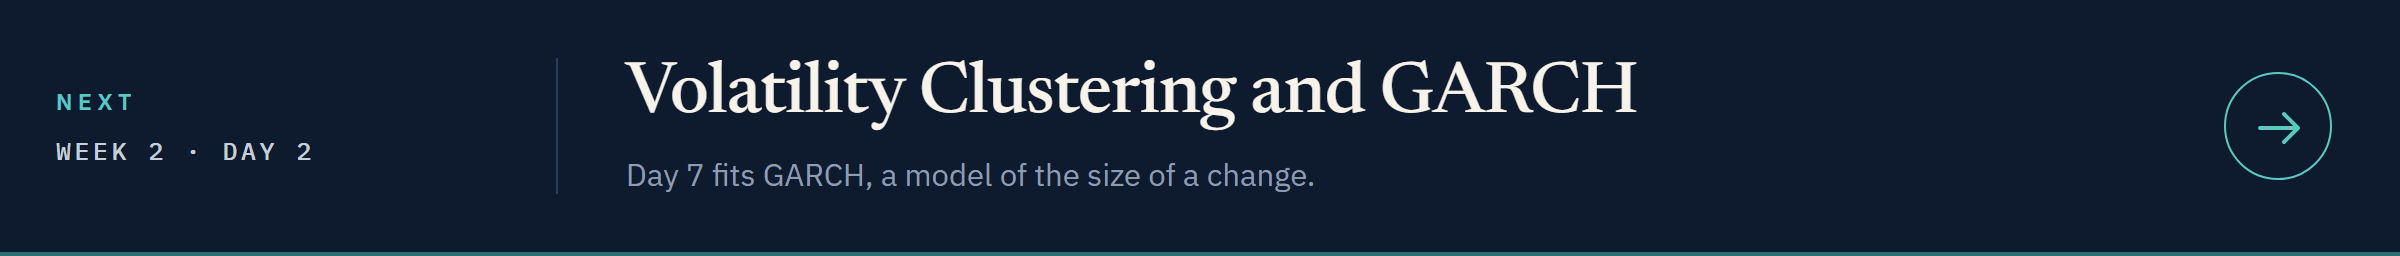](../day2/07_volatility_clustering_and_garch.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day2/07_volatility_clustering_and_garch.ipynb)